# 06. 전이학습 (Transfer Learning)

한 작업에서 학습한 모델의 지식을, 데이터가 적은 다른 작업에 재사용하는 방법입니다.

이 노트북에서는 MNIST 손글씨 숫자를 두 작업으로 나눕니다.
- **원본 작업(source)**: 숫자 0~4를 많은 데이터(약 30,000장)로 학습
- **목표 작업(target)**: 처음 보는 숫자 5~9를 **클래스당 10장**만으로 학습

**학습 목표**
- 사전학습한 모델의 특징 추출부(backbone)를 다른 작업에 재사용한다
- 레이어를 고정(freeze)하고 분류층만 학습하는 특징 추출(feature extraction)을 해 본다
- 전체를 미세조정(fine-tuning)하고, 처음부터 학습한 경우와 비교한다
- 목표 작업의 데이터 양에 따라 전이학습의 효과가 어떻게 달라지는지 확인한다

데이터: `data/downloads/` (MNIST, 첫 실행 시 자동 다운로드, git 제외), 사전학습 모델: `data/pretrained_source.pt` (git 제외)

In [1]:
import torch

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, device: {device}")

PyTorch 2.14.1, device: cpu


## 1. 데이터 준비

데이터가 작으므로 전체를 텐서로 올려 정규화하고, 클래스 번호로 두 작업을 나눕니다. 목표 작업의 라벨 5~9는 0~4로 바꿉니다.

In [2]:
from pathlib import Path
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset

DATA = Path("data")
train_full = datasets.MNIST(DATA / "downloads", train=True, download=True)
test_full = datasets.MNIST(DATA / "downloads", train=False, download=True)

def to_tensors(ds):
    x = (ds.data.float() / 255 - 0.1307) / 0.3081
    return x.unsqueeze(1), ds.targets

x_train, y_train = to_tensors(train_full)
x_test, y_test = to_tensors(test_full)

source_train = TensorDataset(x_train[y_train < 5], y_train[y_train < 5])
source_test = TensorDataset(x_test[y_test < 5], y_test[y_test < 5])
target_test = TensorDataset(x_test[y_test >= 5], y_test[y_test >= 5] - 5)

def target_subset(n_per_class, seed=0):
    """목표 작업(5~9) 학습 데이터에서 클래스당 n_per_class장을 뽑는다."""
    g = torch.Generator().manual_seed(seed)
    idx = torch.cat([
        (y_train == c).nonzero().flatten()[torch.randperm((y_train == c).sum().item(), generator=g)[:n_per_class]]
        for c in range(5, 10)
    ])
    return TensorDataset(x_train[idx], y_train[idx] - 5)

target_train = target_subset(10)
print(f"원본 작업(0~4): train {len(source_train)} | test {len(source_test)}")
print(f"목표 작업(5~9): train {len(target_train)} | test {len(target_test)}")

원본 작업(0~4): train 30596 | test 5139
목표 작업(5~9): train 50 | test 4861


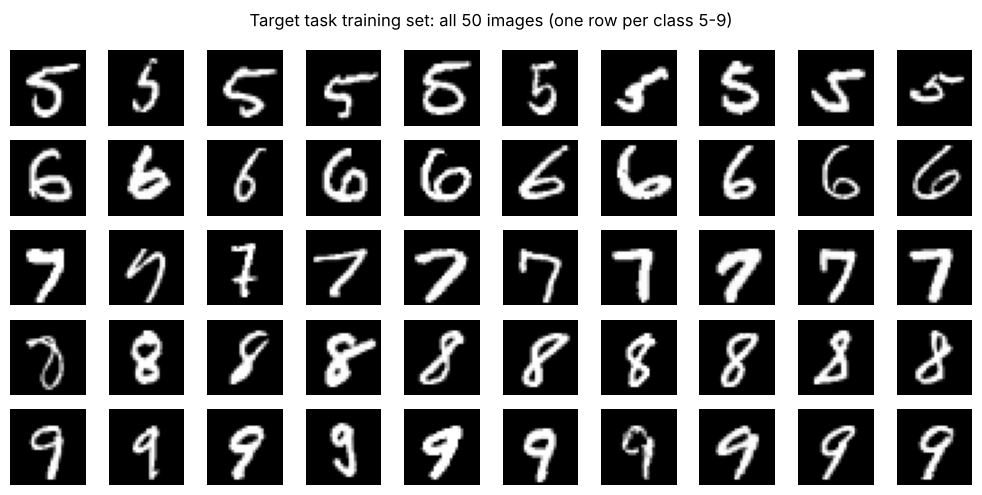

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 10, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(target_train[i][0][0], cmap="gray")
    ax.axis("off")
plt.suptitle("Target task training set: all 50 images (one row per class 5-9)")
plt.tight_layout()
plt.show()

## 2. 모델과 학습 함수

특징 추출부(`features`)와 분류층(`head`)을 분리해 두면 분류층만 바꿔 끼우기 쉽습니다.

데이터 양이 다른 경우를 공정하게 비교하기 위해 epoch가 아니라 **step(배치) 수**를 기준으로 학습합니다.
`frozen_features=True`이면 학습 중에도 `features`를 평가 모드로 두어 BatchNorm 통계까지 고정합니다.

In [4]:
from torch import nn

class CNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        self.head = nn.Linear(128, num_classes)

    def forward(self, x):
        return self.head(self.features(x))

def train(model, dataset, steps, param_groups, frozen_features=False, batch_size=64):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(param_groups)
    criterion = nn.CrossEntropyLoss()
    step = 0
    while step < steps:
        model.train()
        if frozen_features:
            model.features.eval()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            criterion(model(x), y).backward()
            optimizer.step()
            step += 1
            if step == steps:
                break

@torch.no_grad()
def accuracy(model, dataset):
    model.eval()
    correct = 0
    for x, y in DataLoader(dataset, batch_size=1000):
        correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(dataset)

## 3. 원본 작업(0~4)으로 사전학습

In [5]:
pretrained_path = DATA / "pretrained_source.pt"

source_model = CNN().to(device)
train(source_model, source_train, steps=2 * len(source_train) // 64,   # 약 2 epoch
      param_groups=source_model.parameters())
print(f"원본 작업 test acc: {accuracy(source_model, source_test):.3f}")
torch.save(source_model.state_dict(), pretrained_path)
print("저장:", pretrained_path)

원본 작업 test acc: 0.981
저장: data/pretrained_source.pt


## 4. 목표 작업(5~9): 세 가지 방법 비교

| 방법 | 초기 가중치 | 학습하는 파라미터 | 학습률 |
|---|---|---|---|
| A. 처음부터 학습 (scratch) | 무작위 | 전체 | 1e-3 |
| B. 특징 추출 (feature extraction) | 사전학습 | 새 분류층만 (`features` 고정) | 1e-3 |
| C. 미세조정 (fine-tuning) | 사전학습 | 전체 | `features` 1e-4, 분류층 1e-3 |

미세조정에서는 이미 학습된 `features`가 크게 망가지지 않도록 더 작은 학습률을 줍니다.

In [6]:
STEPS = 500

def load_pretrained():
    model = CNN().to(device)
    model.load_state_dict(torch.load(pretrained_path, map_location=device))
    model.head = nn.Linear(128, 5).to(device)   # 분류층을 새 작업용으로 교체
    return model

def run(method, dataset, seed=0):
    torch.manual_seed(seed)
    if method == "scratch":
        model = CNN().to(device)
        train(model, dataset, STEPS, model.parameters())
    elif method == "feature extraction":
        model = load_pretrained()
        for p in model.features.parameters():
            p.requires_grad = False
        train(model, dataset, STEPS, model.head.parameters(), frozen_features=True)
    elif method == "fine-tuning":
        model = load_pretrained()
        train(model, dataset, STEPS, [
            {"params": model.features.parameters(), "lr": 1e-4},
            {"params": model.head.parameters(), "lr": 1e-3},
        ])
    return model

METHODS = ["scratch", "feature extraction", "fine-tuning"]
models = {m: run(m, target_train) for m in METHODS}
for m, model in models.items():
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{m:20s} | 학습 파라미터 {trainable:6,} | test acc {accuracy(model, target_test):.3f}")

scratch              | 학습 파라미터 93,765 | test acc 0.785


feature extraction   | 학습 파라미터    645 | test acc 0.830


fine-tuning          | 학습 파라미터 93,765 | test acc 0.883


## 5. 데이터 양에 따른 효과

목표 작업의 클래스당 학습 이미지 수를 바꿔 가며 세 방법을 비교합니다. (CPU에서 1~2분 정도 걸립니다.)

In [7]:
N_LIST = [5, 10, 30, 100]
curve = {m: [] for m in METHODS}
for n in N_LIST:
    ds = target_subset(n)
    for m in METHODS:
        curve[m].append(accuracy(run(m, ds), target_test))
    print(f"클래스당 {n:3d}장 | " + " | ".join(f"{m} {curve[m][-1]:.3f}" for m in METHODS))

클래스당   5장 | scratch 0.702 | feature extraction 0.758 | fine-tuning 0.834


클래스당  10장 | scratch 0.785 | feature extraction 0.830 | fine-tuning 0.883


클래스당  30장 | scratch 0.909 | feature extraction 0.825 | fine-tuning 0.934


클래스당 100장 | scratch 0.960 | feature extraction 0.838 | fine-tuning 0.959


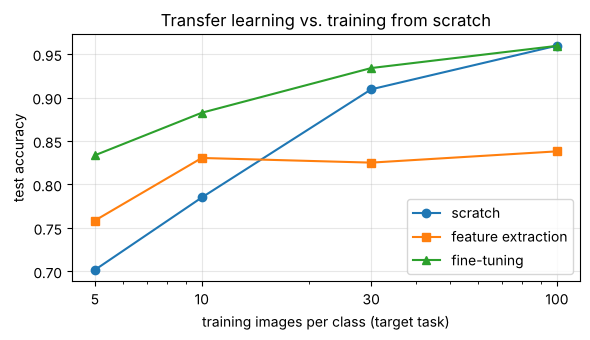

In [8]:
plt.figure(figsize=(6, 3.5))
for m, marker in zip(METHODS, ["o", "s", "^"]):
    plt.plot(N_LIST, curve[m], marker=marker, label=m)
plt.xscale("log")
plt.xticks(N_LIST, N_LIST)
plt.xlabel("training images per class (target task)")
plt.ylabel("test accuracy")
plt.title("Transfer learning vs. training from scratch")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 6. 예측 확인 (클래스당 10장으로 미세조정한 모델)

틀린 예측은 빨간색으로 표시합니다.

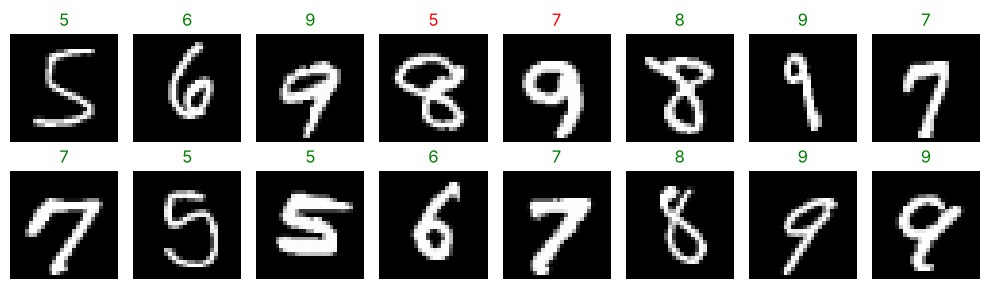

In [9]:
x, y = next(iter(DataLoader(target_test, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(1))))
model = models["fine-tuning"]
model.eval()
with torch.no_grad():
    pred = model(x.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(x[i, 0], cmap="gray")
    ax.set_title(pred[i].item() + 5, color="green" if pred[i] == y[i] else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. 실무에서: ImageNet 사전학습 모델 사용

실제로는 대규모 데이터셋(ImageNet)으로 사전학습된 모델을 내려받아 같은 방식으로 사용합니다. 분류층을 교체하고, backbone을 고정하거나 미세조정하는 방법은 이 노트북과 같습니다. (가중치를 `download.pytorch.org`에서 받으므로 인터넷 연결이 필요합니다.)

```python
from torchvision import models

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)
for p in model.parameters():                             # backbone 고정
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, num_classes)  # 분류층 교체
preprocess = weights.transforms()                        # 사전학습 때와 같은 전처리 (224×224, ImageNet 정규화)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
```

## 요약
- 사전학습 모델의 특징 추출부는 처음 보는 클래스에도 쓸 수 있는 일반적인 특징(획, 곡선 등)을 담고 있다
- 목표 작업의 데이터가 적을수록 전이학습의 효과가 크고, 데이터가 충분하면 처음부터 학습한 경우와 차이가 줄어든다
- 특징 추출은 학습할 파라미터가 적어 데이터가 아주 적을 때 유리하지만, 고정된 특징의 한계 때문에 성능이 일찍 정체된다
- 미세조정은 backbone에 작은 학습률을 주어 전체를 조정하며, 대부분의 경우 가장 좋은 성능을 낸다
- BatchNorm이 있는 모델을 고정할 때는 `eval()` 상태도 함께 고정해야 한다